# 04 · Modelado: CNN entrenada desde cero

**Fase 4 de CRISP-DM.** Clasificar la calidad (*good / regular / bad*) con una CNN pequeña que recibe la **fruta
segmentada** (fondo gris, 128×128), para que no aprenda el fondo (notebooks 02 y 03).

Protocolo:
- Se entrena con `train`; early stopping (y época elegida) por **macro-F1 en `val`**.
- **Configuración principal: `filtros_x2`**, no la de mayor macro-F1 en `val` (`sin_aumento`). La regla inicial era
  el máximo; se cambió tras ver `val`, sin mirar `test` ni `test_propias` (motivos en la sección 3).
- `test` y `test_propias` **no se usan aquí**: se evalúan una sola vez en el notebook 05.
- El entrenamiento está en `src/training/entrenar_cnn.py` (horas en CPU). Este notebook analiza sus resultados;
  para regenerarlos: `python -m src.training.entrenar_cnn`.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.config import FRUITS, QUALITY_CLASSES, RESULTS_DIR, SEED
from src.data.carga import cargar_splits
from src.data.tensores import aumentar, cargar_tensores, media_desv
from src.evaluation.metricas import resumen, tabla
from src.models.cnn import CNNCalidad, n_parametros
from src.training.entrenar_cnn import EXPERIMENTOS, SALIDA, cargar_checkpoint, predecir, resultado

FIG_DIR = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "svg.fonttype": "none"})
COLS = ["macro-F1", "acc. balanceada", "kappa", "F1 good", "F1 regular", "F1 bad", "recall regular", "recall bad"]
sel = json.loads((SALIDA / "seleccion.json").read_text(encoding="utf-8"))
mejor = sel["mejor"]
val = cargar_splits("val")
print("Configuración principal:", mejor, "|", resultado(mejor)["cfg"])

Configuración principal: filtros_x2 | {'enmascarar': True, 'aumento': True, 'balance': 'pesos', 'lr': 0.001, 'dropout': 0.3, 'filtros': [32, 64, 128], 'wd': 0.0001, 'lote': 64, 'epocas': 100, 'paciencia': 15, 'semilla': 42}


## 1. Entrada y aumento de datos

Arriba, la entrada; abajo, una versión aumentada. El aumento se aplica solo en `train` y al vuelo: espejos, rotación
±30°, escala ×0,6–1,2, traslación, y brillo, contraste y saturación **solo sobre la fruta** (el fondo gris no cambia).
No se altera el tono, porque el color forma parte de la definición de calidad.

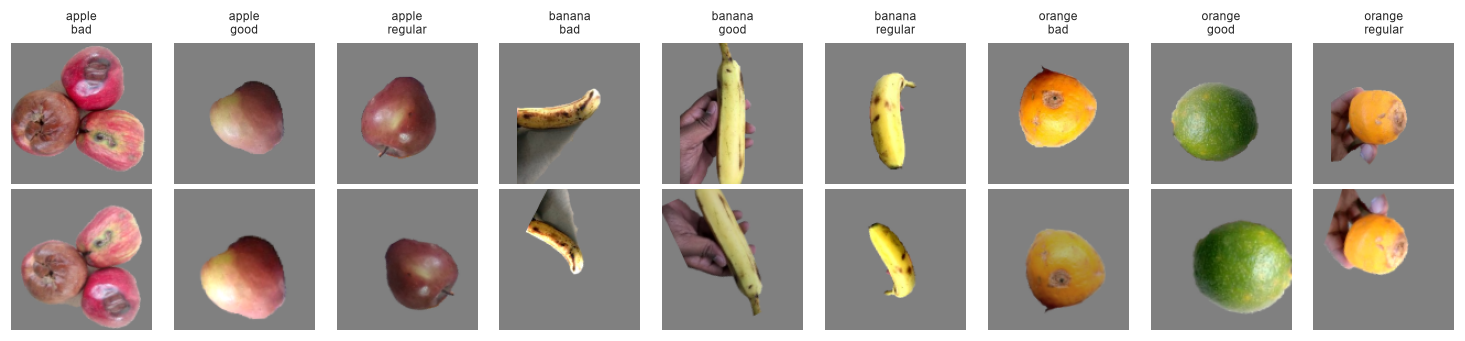

In [2]:
torch.manual_seed(SEED)
muestra = cargar_splits("train").groupby(["fruit", "quality"]).sample(1, random_state=SEED)
x, a, _ = cargar_tensores(muestra)
z = aumentar(x.float() / 255, a.float() / 255, "gris").clamp(0, 1)
fig, axes = plt.subplots(2, len(x), figsize=(1.5 * len(x), 3.2))
for k in range(len(x)):
    axes[0, k].imshow(x[k].permute(1, 2, 0)); axes[1, k].imshow(z[k].permute(1, 2, 0))
    axes[0, k].set_title(f"{muestra.fruit.iloc[k]}\n{muestra.quality.iloc[k]}", fontsize=8)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR / "cnn_aumento.png", dpi=150); plt.show()

## 2. Arquitectura

In [3]:
m = CNNCalidad(filtros=resultado(mejor)["cfg"]["filtros"])
print(m); print("Parámetros:", n_parametros(m))

CNNCalidad(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Linear(in_features=128,

## 3. Experimentos: hiperparámetros y ablaciones

Cada fila cambia una sola cosa respecto a `base` (lr 1e-3, pesos de clase, con aumento, filtros 16-32-64).

`sin_aumento` obtiene el mayor macro-F1 en `val`, pero se elige `filtros_x2`: la diferencia (0,007) equivale a acertar
unas 2 *regular* de 32; conserva el aumento, pensado para las fotos propias (más oscuras, fruta más pequeña) y que `val`
(Kaggle) no puede premiar; y tiene mejor F1 de *regular* y menor brecha train-val. `sin_aumento` queda como ablación.

In [4]:
t = tabla({n: resultado(n)["val"] for n in EXPERIMENTOS}, COLS)
t.insert(0, "mejor época", [resultado(n)["mejor_epoca"] for n in t.index])
t.insert(1, "épocas", [resultado(n)["epocas"] for n in t.index])
t.insert(2, "minutos", [round(resultado(n)["segundos"] / 60) for n in t.index])
t.to_csv(RESULTS_DIR / "cnn_experimentos_val.csv"); t

,mejor época,épocas,minutos,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
base,66,81,38,0.631,0.688,0.656,0.832,0.175,0.885,0.438,0.885
lr_3e-3,47,62,28,0.636,0.750,0.633,0.803,0.212,0.894,0.688,0.870
sin_balance,81,96,43,0.607,0.618,0.796,0.902,0.000,0.918,0.000,0.930
sin_aumento,42,57,21,0.656,0.710,0.705,0.861,0.200,0.907,0.438,0.883
filtros_x2,40,55,52,0.648,0.746,0.659,0.820,0.231,0.894,0.625,0.892


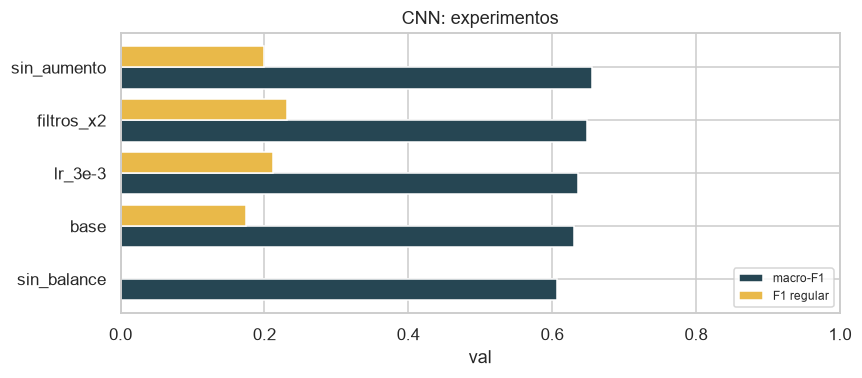

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
o = t.sort_values("macro-F1")
o[["macro-F1", "F1 regular"]].plot.barh(ax=ax, color=["#264653", "#e9b949"], width=0.8)
ax.set(xlim=(0, 1), xlabel="val", title="CNN: experimentos"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "cnn_experimentos.svg"); plt.show()

## 4. Curvas de entrenamiento

Train y val se miden igual (modo evaluación, sin aumento, misma pérdida). La línea vertical es la época elegida.

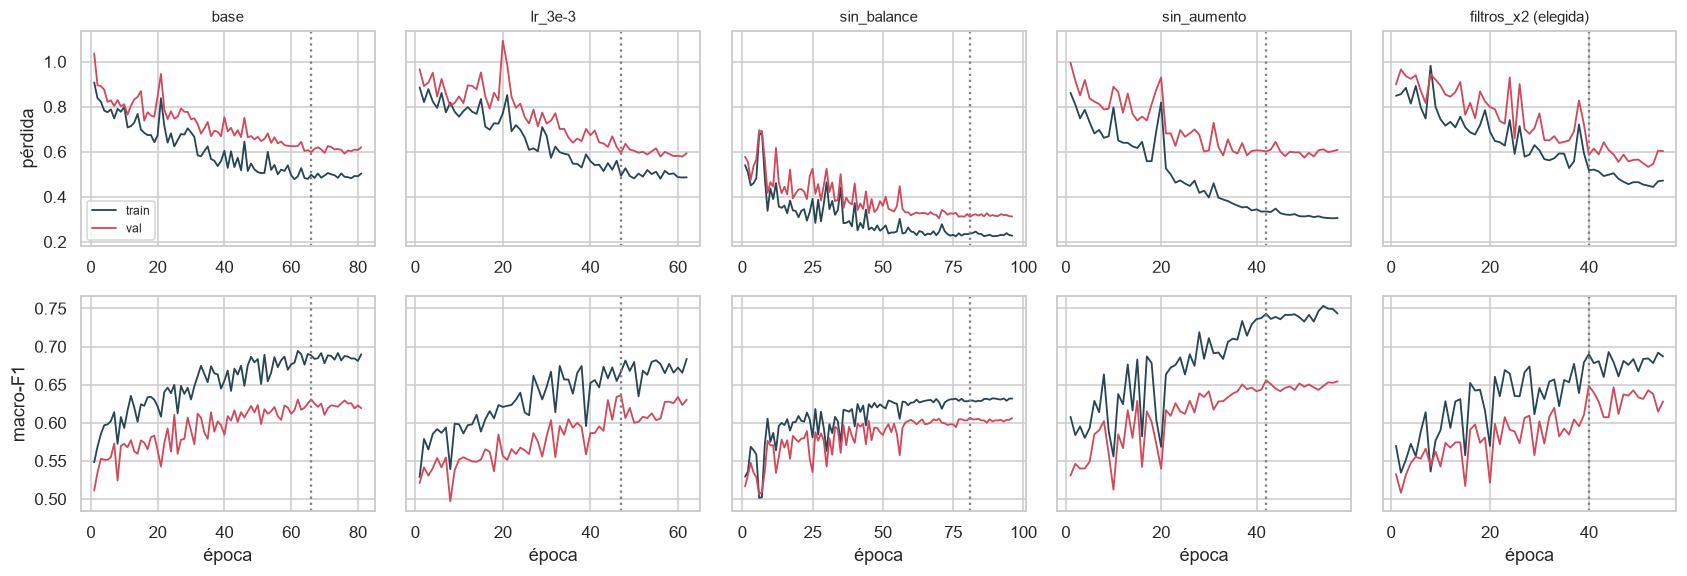

,f1_train,f1_val,brecha
base,0.688,0.631,0.058
lr_3e-3,0.667,0.636,0.031
sin_balance,0.629,0.607,0.022
sin_aumento,0.743,0.656,0.087
filtros_x2,0.690,0.649,0.042


In [6]:
fig, axes = plt.subplots(2, len(EXPERIMENTOS), figsize=(3.1 * len(EXPERIMENTOS), 5.4), sharey="row")
for k, n in enumerate(EXPERIMENTOS):
    h = pd.read_csv(SALIDA / f"{n}.csv")
    for f, met in enumerate(["loss", "f1"]):
        for s, col in (("train", "#264653"), ("val", "#d1495b")):
            axes[f, k].plot(h.epoca, h[f"{met}_{s}"], color=col, label=s, lw=1.2)
        axes[f, k].axvline(resultado(n)["mejor_epoca"], color="gray", ls=":")
    axes[0, k].set_title(n + (" (elegida)" if n == mejor else ""), fontsize=10); axes[1, k].set_xlabel("época")
axes[0, 0].set_ylabel("pérdida"); axes[1, 0].set_ylabel("macro-F1"); axes[0, 0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "cnn_curvas.svg"); plt.show()

brecha = pd.DataFrame({n: pd.read_csv(SALIDA / f"{n}.csv").set_index("epoca").loc[resultado(n)["mejor_epoca"], ["f1_train", "f1_val"]]
                       for n in EXPERIMENTOS}).T
brecha["brecha"] = brecha.f1_train - brecha.f1_val
brecha.round(3)

## 5. Estabilidad entre semillas y efecto del fondo (val)

Con 2 semillas solo se ve cuánto difieren dos corridas: no alcanza para una desviación estándar fiable. La red con
imagen completa es una sola corrida. Además, `val` comparte los fondos de Kaggle; la prueba del atajo es
`test_propias` (notebook 05).

In [7]:
filas = {f"fruta · {n}": resultado(n)["val"] for n in sel["semillas_fruta"]}
filas |= {f"imagen completa · {n}": resultado(n)["val"] for n in sel["semillas_completa"]}
extra = ["sin_aumento", "sin_aumento_s43", "sin_aumento_completa_s42"]   # ablación repetida
filas |= {f"ablación · {n}": resultado(n)["val"] for n in extra}
tabla(filas, COLS)

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
fruta · filtros_x2,0.648,0.746,0.659,0.820,0.231,0.894,0.625,0.892
fruta · filtros_x2_s43,0.668,0.799,0.675,0.827,0.276,0.901,0.781,0.897
imagen completa · filtros_x2_completa_s42,0.679,0.756,0.724,0.839,0.265,0.933,0.562,0.953
ablación · sin_aumento,0.656,0.710,0.705,0.861,0.200,0.907,0.438,0.883
ablación · sin_aumento_s43,0.654,0.728,0.680,0.829,0.225,0.907,0.531,0.876
ablación · sin_aumento_completa_s42,0.642,0.662,0.722,0.844,0.152,0.929,0.250,0.942


## 6. Comparación con el ML clásico en val

In [8]:
comp = pd.read_csv(RESULTS_DIR / "ml_clasico_val.csv", index_col=0)
comp.loc[f"CNN ({mejor})"] = tabla({"c": resultado(mejor)["val"]}, COLS).loc["c"]
comp = comp.sort_values("macro-F1", ascending=False); comp.to_csv(RESULTS_DIR / "comparacion_val.csv"); comp

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
SVM (RBF),0.727,0.780,0.802,0.903,0.333,0.944,0.531,0.942
XGBoost,0.673,0.665,0.821,0.915,0.167,0.937,0.125,0.953
CNN (filtros_x2),0.648,0.746,0.659,0.820,0.231,0.894,0.625,0.892
KNN,0.647,0.644,0.819,0.912,0.093,0.937,0.062,0.957
Random Forest,0.629,0.626,0.741,0.871,0.118,0.899,0.094,0.903
Regresión logística,0.602,0.653,0.597,0.800,0.152,0.853,0.406,0.827
Dummy (aleatorio estratificado),0.311,0.311,-0.058,0.459,0.031,0.442,0.031,0.436
Dummy (clase mayoritaria),0.216,0.333,0.000,0.648,0.000,0.000,0.000,0.000


## 7. Análisis del modelo elegido

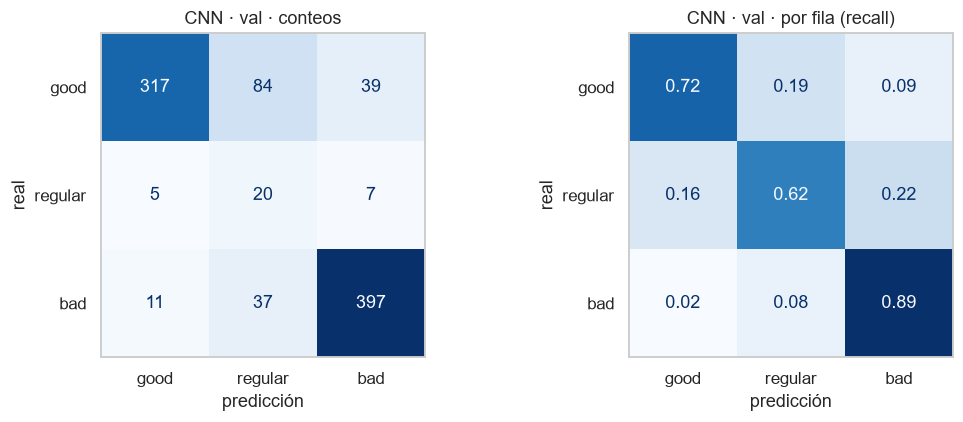

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
apple,0.560,0.617,0.498,0.759,0.129,0.792,0.462,0.766
banana,0.837,0.953,0.885,0.923,0.600,0.988,1.000,0.984
orange,0.641,0.720,0.676,0.808,0.200,0.915,0.500,0.940


In [9]:
modelo, media, desv, cfg = cargar_checkpoint(mejor)
xva, _, yva = cargar_tensores(val, cfg["enmascarar"])
logits = predecir(modelo, xva, media, desv); pred = logits.argmax(1).numpy(); y = yva.numpy()
assert abs(resumen(y, pred)["macro-F1"] - resultado(mejor)["val"]["macro-F1"]) < 1e-3   # el checkpoint reproduce el resultado
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, tt in [(axes[0], None, "conteos"), (axes[1], "true", "por fila (recall)")]:
    ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize=norm), display_labels=QUALITY_CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.grid(False); ax.set(title=f"CNN · val · {tt}", xlabel="predicción", ylabel="real")
fig.tight_layout(); fig.savefig(FIG_DIR / "cnn_confusion_val.svg"); plt.show()
tabla({f: resumen(y[val.fruit == f], pred[val.fruit == f]) for f in FRUITS}, COLS)

## 8. Conclusiones

1. **La CNN supera a la línea base, pero no al SVM en `val`**: macro-F1 0,648 (semilla 42) y 0,668 (semilla 43), frente a
   0,727 del SVM y 0,22–0,31 de los clasificadores triviales. La comparación final es la del notebook 05.
2. **Detecta más *regular* que el SVM, con muchas falsas alarmas.** Recall 0,62 (20 de 32) frente a 0,53, pero de 141
   predicciones *regular* solo 20 son correctas (precisión 0,14): 84 *good* y 37 *bad* se marcan como *regular*.
   Por eso el F1 de *regular* es 0,23 (SVM: 0,33).
3. **Los pesos de clase son imprescindibles.** Sin ellos nunca predice *regular* (recall 0), aunque kappa sube de
   0,656 a 0,796 (`base` frente a `sin_balance`): otra vez, las métricas dominadas por las clases grandes lo ocultan.
4. **En `val` el aumento no ayuda.** Sin él, la red pequeña pasa de 0,631 a 0,656, a costa de una brecha train-val
   mayor (0,087 frente a 0,058). `val` es Kaggle: si el aumento sirve para las fotos propias se verá en el notebook 05.
5. **Sobreajuste moderado; la limitación no es solo memorizar.** La brecha de la CNN principal es 0,042 y su macro-F1
   en train es apenas 0,69. Doblar los filtros sube `val` de 0,631 a 0,649, dentro de lo que varía entre semillas.
6. **Las diferencias entre variantes con pesos son pequeñas** (0,631–0,656) y la variación entre dos semillas de
   `filtros_x2` es 0,019: no permiten afirmar que una configuración sea mejor. Además, la época y la configuración se
   eligieron con `val`, así que estas cifras son algo optimistas.
7. **En `val` la imagen completa no pierde frente a la fruta**: 0,679 frente a 0,648 y 0,668 (una sola corrida). `val`
   comparte los fondos de Kaggle; la prueba del atajo es `test_propias` (notebook 05).
8. **La manzana es la más difícil** (macro-F1 0,56) y el banano la más fácil (0,84), igual que con el SVM. Con 9–13
   *regular* por fruta, estas cifras tienen mucha incertidumbre.